# AutoPredict — EDA & Préparation des données

**Objectif :** explorer le dataset brut, comprendre sa qualité, puis appliquer
et visualiser le pipeline de nettoyage (`ml/src/preprocessing.py`) étape par étape.


## 1. Import des bibliothèques

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 2. Chargement du dataset brut

Le fichier utilise l'encodage **latin-1** (pas UTF-8), sinon `UnicodeDecodeError`.

In [2]:
RAW_PATH = '../data/raw/avito_car_dataset_ALL.csv'
PROCESSED_PATH = '../data/processed/cars_clean.csv'

df = pd.read_csv(RAW_PATH, encoding='latin-1')

print("Shape brute :", df.shape)
df.head()

Shape brute : (24776, 32)


,Unnamed: 0,Lien,Ville,Secteur,Marque,Modèle,Année-Modèle,Kilométrage,Type de carburant,Puissance fiscale,Boite de vitesses,Nombre de portes,Origine,Première main,État,Jantes aluminium,Airbags,Climatisation,Système de navigation/GPS,Toit ouvrant,Sièges cuir,Radar de recul,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
0,0,https://www.avito.ma/fr/massira_2/voitures/FIA...,Temara,Massira 2,Fiat,Punto,2007,200 000 - 249 999,Diesel,5,Manuelle,5.0,WW au Maroc,Non,Très bon,False,False,True,False,False,False,False,False,False,True,False,False,False,True,False,False,60000
1,1,https://www.avito.ma/fr/temara/voitures/Dacia_...,Temara,NaN,Dacia,Dokker Van,2013,400 000 - 449 999,Diesel,6,Manuelle,3.0,WW au Maroc,Non,Excellent,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,70000
2,2,https://www.avito.ma/fr/casablanca/voitures/Da...,Casablanca,NaN,Dacia,Dokker,2014,160 000 - 169 999,Diesel,6,Manuelle,5.0,WW au Maroc,NaN,Très bon,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,90000
3,3,https://www.avito.ma/fr/casablanca/voitures/to...,Casablanca,NaN,Volkswagen,Touareg,2005,0 - 4 999,Diesel,10,Automatique,5.0,WW au Maroc,Oui,Excellent,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,90000
4,4,https://www.avito.ma/fr/dakhla/voitures/Toyota...,Dakhla,NaN,Toyota,Prado,2007,200 000 - 249 999,Diesel,12,Manuelle,5.0,WW au Maroc,Non,Excellent,False,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False,97000


## 3. Suppression des vraies annonces dupliquées

On détecte les doublons via la colonne `Lien` (URL unique de l'annonce) **avant**
de sélectionner les colonnes finales. Si on le faisait après, on risquerait de
supprimer des voitures différentes qui se ressemblent juste sur les critères gardés
(ex: deux Logan 2015 diesel à Casablanca).

In [3]:
nb_doublons = df.duplicated(subset=['Lien']).sum()
print(f"Annonces dupliquées (même Lien) : {nb_doublons}")

df = df.drop_duplicates(subset=['Lien'])
print(f"Shape après suppression : {df.shape}")

Annonces dupliquées (même Lien) : 16546
Shape après suppression : (8230, 32)


## 4. Sélection des critères utiles au modèle

On ne garde que les colonnes définies pour le modèle, et on les renomme en
minuscules sans accents (plus pratique pour la suite du pipeline / le code Python).

In [4]:
COLONNES_A_GARDER = [
    "Marque", "Modèle", "Année-Modèle", "Kilométrage", "Type de carburant",
    "Boite de vitesses", "Puissance fiscale", "État", "Ville",
    "Première main", "Prix",
]

RENAME_MAP = {
    "Marque": "marque", "Modèle": "modele", "Année-Modèle": "annee",
    "Kilométrage": "kilometrage", "Type de carburant": "carburant",
    "Boite de vitesses": "boite_vitesses", "Puissance fiscale": "puissance_fiscale",
    "État": "etat", "Ville": "ville", "Première main": "premiere_main", "Prix": "prix",
}

df = df[COLONNES_A_GARDER].copy()
df = df.rename(columns=RENAME_MAP)

print("Shape après sélection :", df.shape)
df.head()

Shape après sélection : (8230, 11)


,marque,modele,annee,kilometrage,carburant,boite_vitesses,puissance_fiscale,etat,ville,premiere_main,prix
0,Fiat,Punto,2007,200 000 - 249 999,Diesel,Manuelle,5,Très bon,Temara,Non,60000
1,Dacia,Dokker Van,2013,400 000 - 449 999,Diesel,Manuelle,6,Excellent,Temara,Non,70000
2,Dacia,Dokker,2014,160 000 - 169 999,Diesel,Manuelle,6,Très bon,Casablanca,NaN,90000
3,Volkswagen,Touareg,2005,0 - 4 999,Diesel,Automatique,10,Excellent,Casablanca,Oui,90000
4,Toyota,Prado,2007,200 000 - 249 999,Diesel,Manuelle,12,Excellent,Dakhla,Non,97000


## 5. EDA — État des lieux avant nettoyage

In [5]:
print("Valeurs manquantes (%) :")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

print("\nStatistiques du prix (brut) :")
print(df['prix'].describe())

Valeurs manquantes (%) :
etat                 26.9
premiere_main        25.1
marque                0.0
annee                 0.0
modele                0.0
kilometrage           0.0
carburant             0.0
puissance_fiscale     0.0
boite_vitesses        0.0
ville                 0.0
prix                  0.0
dtype: float64

Statistiques du prix (brut) :
count    8.230000e+03
mean     2.173126e+05
std      6.761585e+06
min      6.000000e+04
25%      7.500000e+04
50%      1.000000e+05
75%      1.400000e+05
max      6.120372e+08
Name: prix, dtype: float64


### 5.1 Distribution du prix brut (avec valeurs aberrantes)

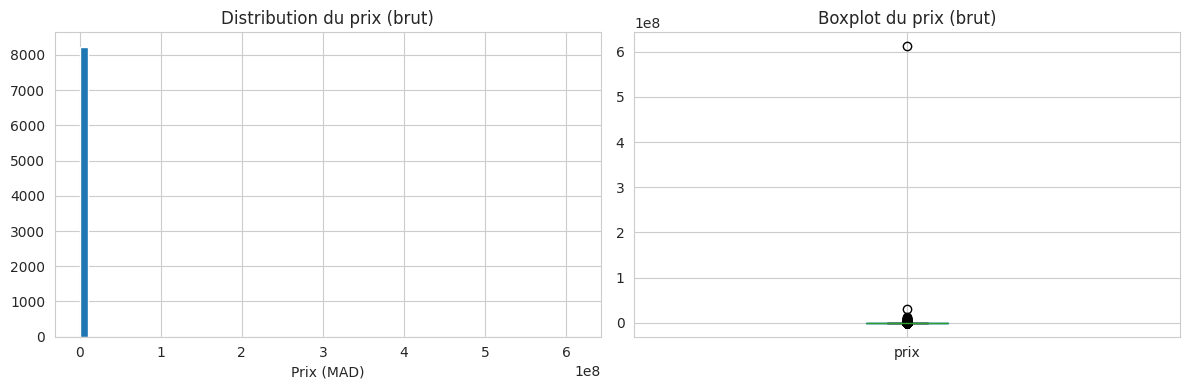

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['prix'].hist(bins=60, ax=axes[0])
axes[0].set_title('Distribution du prix (brut)')
axes[0].set_xlabel('Prix (MAD)')

df.boxplot(column='prix', ax=axes[1])
axes[1].set_title('Boxplot du prix (brut)')

plt.tight_layout()
plt.show()

### 5.2 Valeurs extrêmes du prix

In [7]:
print("Top 10 prix les plus élevés :")
print(df['prix'].sort_values(ascending=False).head(10))

print("\nTop 10 prix les plus bas :")
print(df['prix'].sort_values(ascending=True).head(10))

Top 10 prix les plus élevés :
5622    612037205
8149     31000000
8171     14000000
8130     10000000
7200     10000000
4151      8300000
5864      8300000
298       7800000
7216      6300000
8141      6000000
Name: prix, dtype: int64

Top 10 prix les plus bas :
6969    60000
4895    60000
4889    60000
3426    60000
7667    60000
7662    60000
2344    60000
2537    60000
2526    60000
3000    60000
Name: prix, dtype: int64


## 6. Transformation du kilométrage

Le kilométrage est stocké en tranches textuelles (ex: `'200 000 - 249 999'`).
On extrait les deux bornes numériques et on prend leur **valeur médiane**.

In [8]:
def parse_kilometrage(valeur):
    """Convertit une tranche '200 000 - 249 999' en valeur médiane (224999.5)."""
    if pd.isna(valeur):
        return np.nan
    nombres = re.findall(r"\d[\d\s]*\d|\d", str(valeur))
    nombres = [int(n.replace(" ", "")) for n in nombres]
    if len(nombres) == 2:
        return (nombres[0] + nombres[1]) / 2
    if len(nombres) == 1:
        return float(nombres[0])
    return np.nan

print("Valeurs uniques avant conversion :")
print(df['kilometrage'].unique())

df['kilometrage'] = df['kilometrage'].apply(parse_kilometrage)

print("\nAperçu après conversion :")
print(df['kilometrage'].describe())
print(f"Valeurs manquantes après conversion : {df['kilometrage'].isna().sum()}")

Valeurs uniques avant conversion :
<StringArray>
['200 000 - 249 999', '400 000 - 449 999', '160 000 - 169 999',
         '0 - 4 999', '180 000 - 189 999',   '75 000 - 79 999',
   '10 000 - 14 999', '120 000 - 129 999', '110 000 - 119 999',
   '35 000 - 39 999',   '90 000 - 94 999', '190 000 - 199 999',
   '50 000 - 54 999', '300 000 - 349 999',   '30 000 - 34 999',
   '20 000 - 24 999',   '80 000 - 84 999', '140 000 - 149 999',
 '130 000 - 139 999', '250 000 - 299 999',   '95 000 - 99 999',
 '100 000 - 109 999', '170 000 - 179 999',   '65 000 - 69 999',
     '5 000 - 9 999',   '55 000 - 59 999',   '25 000 - 29 999',
   '70 000 - 74 999',   '15 000 - 19 999', '350 000 - 399 999',
   '60 000 - 64 999',   '40 000 - 44 999',   '45 000 - 49 999',
   '85 000 - 89 999', '150 000 - 159 999', '450 000 - 499 999']
Length: 36, dtype: str

Aperçu après conversion :
count      8230.000000
mean     133026.231470
std       89095.353579
min        2499.500000
25%       62499.500000
50%      124999.50

## 7. Nettoyage des colonnes catégorielles

Plutôt que de supprimer les lignes avec des valeurs manquantes (`état`, `première main`,
`boite_vitesses`), on les impute avec une catégorie explicite **'Inconnu'** — plus
informatif qu'une suppression qui ferait perdre ~25% des données.

In [9]:
df['boite_vitesses'] = df['boite_vitesses'].replace('--', np.nan)

colonnes_categorielles = [
    'marque', 'modele', 'carburant', 'boite_vitesses',
    'etat', 'ville', 'premiere_main',
]

for col in colonnes_categorielles:
    n_missing = df[col].isna().sum()
    if n_missing > 0:
        df[col] = df[col].fillna('Inconnu')
        print(f"'{col}': {n_missing} valeurs manquantes -> 'Inconnu'")

'boite_vitesses': 966 valeurs manquantes -> 'Inconnu'
'etat': 2212 valeurs manquantes -> 'Inconnu'
'premiere_main': 2064 valeurs manquantes -> 'Inconnu'


## 8. Regroupement des modalités rares

`modele` et `ville` ont beaucoup de valeurs uniques (forte cardinalité), ce qui
compliquerait l'encodage. Les modalités apparaissant moins de 15 fois sont
regroupées sous `'Autre'`.

In [10]:
def regrouper_modalites_rares(df, colonne, seuil=15):
    freq = df[colonne].value_counts()
    rares = freq[freq < seuil].index
    df[colonne] = df[colonne].where(~df[colonne].isin(rares), 'Autre')
    print(f"'{colonne}': {len(rares)} modalités rares regroupées sous 'Autre' "
          f"({df[colonne].nunique()} catégories restantes)")
    return df

df = regrouper_modalites_rares(df, 'modele')
df = regrouper_modalites_rares(df, 'ville')

'modele': 259 modalités rares regroupées sous 'Autre' (111 catégories restantes)
'ville': 143 modalités rares regroupées sous 'Autre' (49 catégories restantes)


## 9. Doublons résiduels après sélection des colonnes

In [11]:
n_before = len(df)
df = df.drop_duplicates()
print(f"{n_before - len(df)} doublons supprimés (lignes strictement identiques sur les 11 critères gardés)")
print("Shape :", df.shape)

118 doublons supprimés (lignes strictement identiques sur les 11 critères gardés)
Shape : (8112, 11)


## 10. Suppression des lignes sans feature numérique essentielle

In [12]:
n_before = len(df)
df = df.dropna(subset=['kilometrage', 'annee', 'puissance_fiscale'])
print(f"{n_before - len(df)} lignes supprimées (kilométrage / année / puissance manquants)")
print("Shape :", df.shape)

0 lignes supprimées (kilométrage / année / puissance manquants)
Shape : (8112, 11)


## 11. Suppression des outliers sur le prix (target)

Le prix contient des erreurs de saisie extrêmes (ex: valeurs > 600 millions MAD).
On applique :
1. un **garde-fou métier** (prix plausible pour une occasion au Maroc : 8 000 – 2 000 000 MAD)
2. un **filtrage IQR sur log(prix)**, plus robuste qu'un IQR sur le prix brut vu
   l'asymétrie forte de la distribution.

In [13]:
PRIX_MIN_PLAUSIBLE = 8_000
PRIX_MAX_PLAUSIBLE = 2_000_000

n_before = len(df)
df = df[(df['prix'] >= PRIX_MIN_PLAUSIBLE) & (df['prix'] <= PRIX_MAX_PLAUSIBLE)]

log_prix = np.log1p(df['prix'])
q1, q3 = log_prix.quantile([0.25, 0.75])
iqr = q3 - q1
borne_basse = q1 - 1.5 * iqr
borne_haute = q3 + 1.5 * iqr

df = df[(log_prix >= borne_basse) & (log_prix <= borne_haute)]
df = df.reset_index(drop=True)

print(f"{n_before - len(df)} lignes supprimées au total")
print(f"Bornes retenues : [{np.expm1(borne_basse):.0f}, {np.expm1(borne_haute):.0f}] MAD environ")
print("Shape finale :", df.shape)

209 lignes supprimées au total
Bornes retenues : [29407, 357048] MAD environ
Shape finale : (7903, 11)


## 12. Feature engineering — âge du véhicule

In [14]:
ANNEE_ACTUELLE = 2026
df['age_vehicule'] = ANNEE_ACTUELLE - df['annee']

df[['annee', 'age_vehicule']].describe()

,annee,age_vehicule
count,7903.000000,7903.000000
mean,2011.800709,14.199291
std,5.424327,5.424327
min,1990.000000,4.000000
25%,2008.000000,10.000000
50%,2012.000000,14.000000
75%,2016.000000,18.000000
max,2022.000000,36.000000


## 13. Visualisation du dataset nettoyé

Comparaison avant / après nettoyage et exploration des relations entre variables.

### 13.1 Distribution du prix après nettoyage

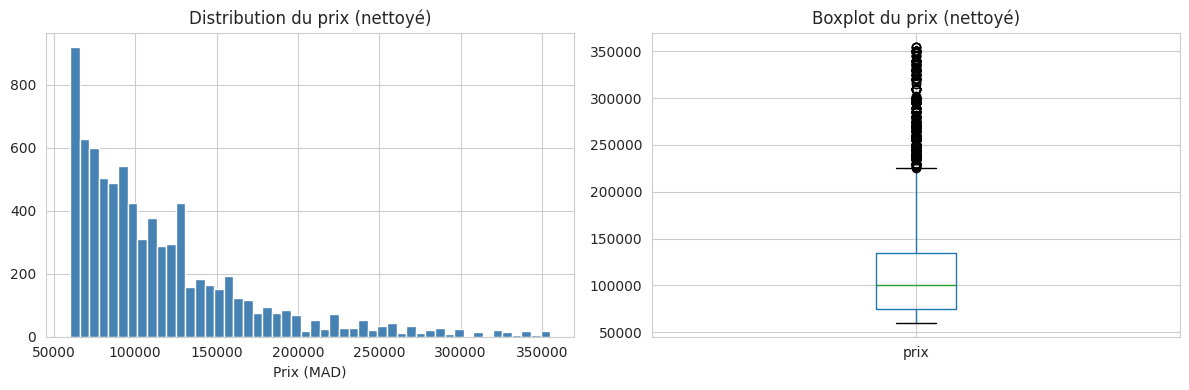

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['prix'].hist(bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution du prix (nettoyé)')
axes[0].set_xlabel('Prix (MAD)')

df.boxplot(column='prix', ax=axes[1])
axes[1].set_title('Boxplot du prix (nettoyé)')

plt.tight_layout()
plt.show()

### 13.2 Corrélations entre variables numériques et le prix

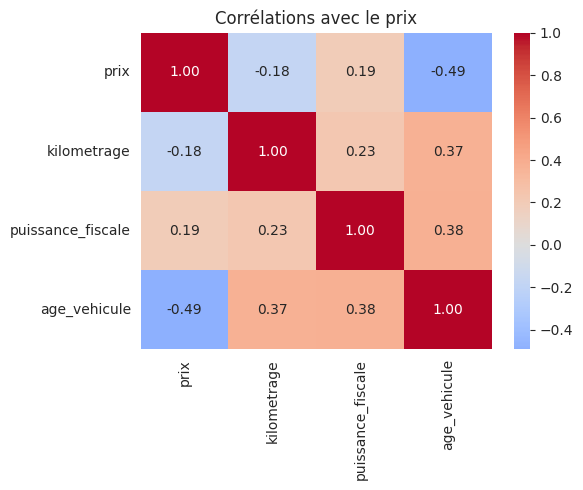

In [16]:
plt.figure(figsize=(6, 5))
correlations = df[['prix', 'kilometrage', 'puissance_fiscale', 'age_vehicule']].corr()
sns.heatmap(correlations, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Corrélations avec le prix')
plt.tight_layout()
plt.show()

### 13.3 Prix moyen par marque (top 15)

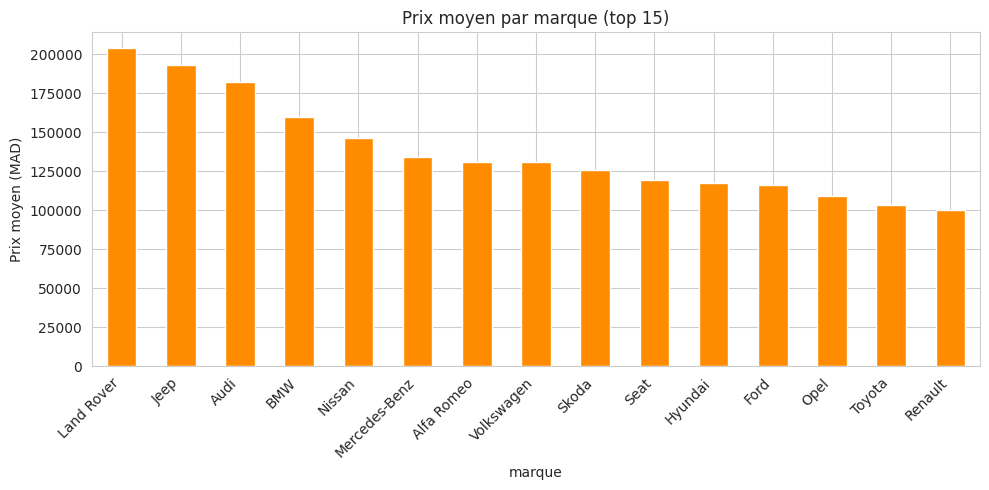

In [17]:
top_marques = df.groupby('marque')['prix'].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
top_marques.plot(kind='bar', color='darkorange')
plt.title('Prix moyen par marque (top 15)')
plt.ylabel('Prix moyen (MAD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 13.4 Nombre d'annonces par marque (top 15)

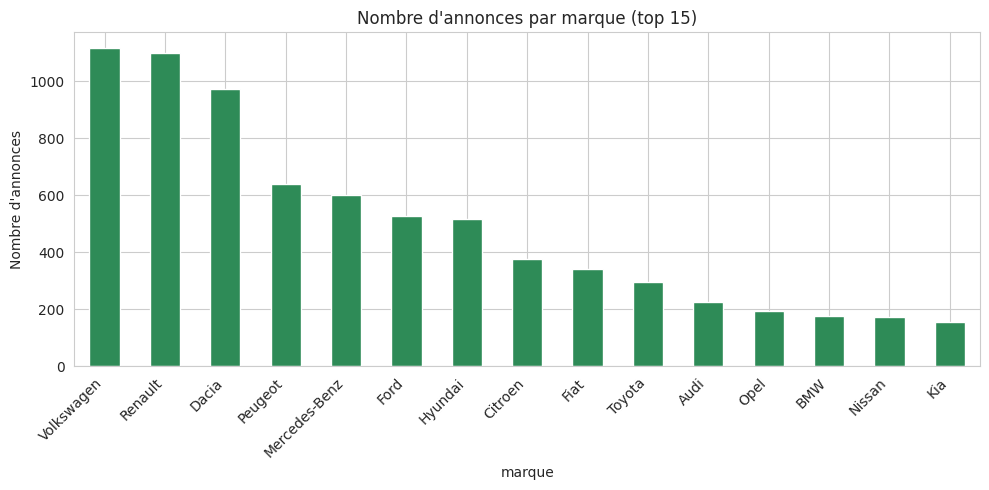

In [18]:
plt.figure(figsize=(10, 5))
df['marque'].value_counts().head(15).plot(kind='bar', color='seagreen')
plt.title("Nombre d'annonces par marque (top 15)")
plt.ylabel("Nombre d'annonces")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 13.5 Relation kilométrage / prix

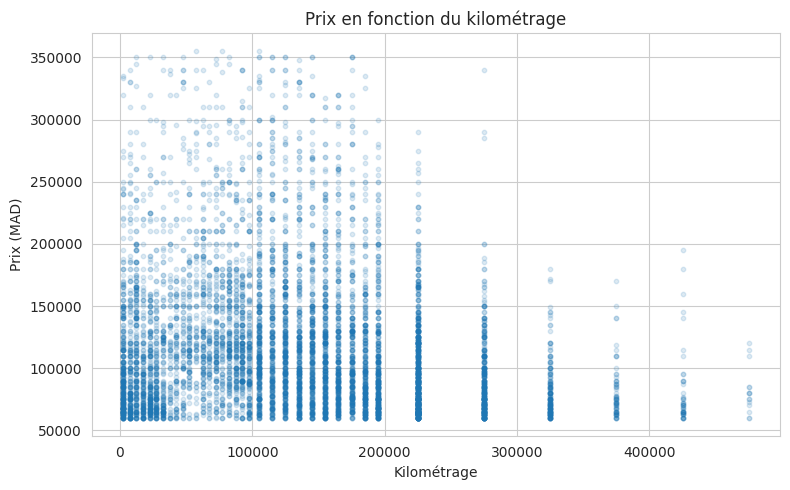

In [19]:
plt.figure(figsize=(8, 5))
plt.scatter(df['kilometrage'], df['prix'], alpha=0.15, s=10)
plt.title('Prix en fonction du kilométrage')
plt.xlabel('Kilométrage')
plt.ylabel('Prix (MAD)')
plt.tight_layout()
plt.show()

### 13.6 Relation âge du véhicule / prix

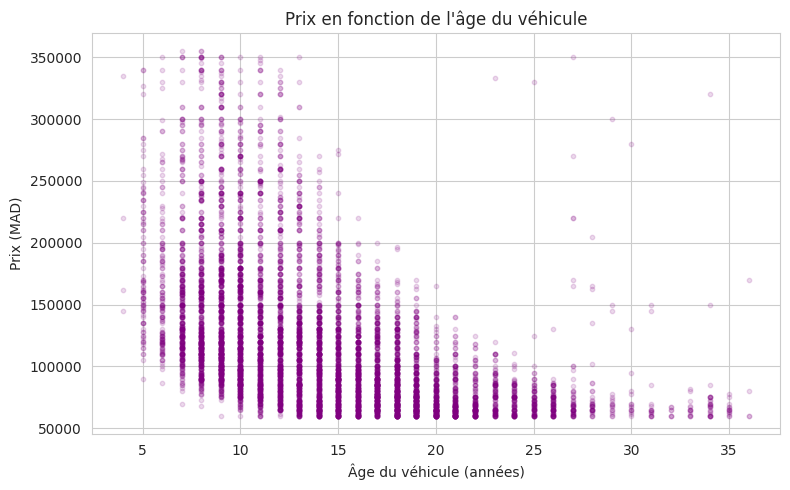

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(df['age_vehicule'], df['prix'], alpha=0.15, s=10, color='purple')
plt.title('Prix en fonction de l\'âge du véhicule')
plt.xlabel('Âge du véhicule (années)')
plt.ylabel('Prix (MAD)')
plt.tight_layout()
plt.show()

### 13.7 Répartition des états et du statut 'première main'

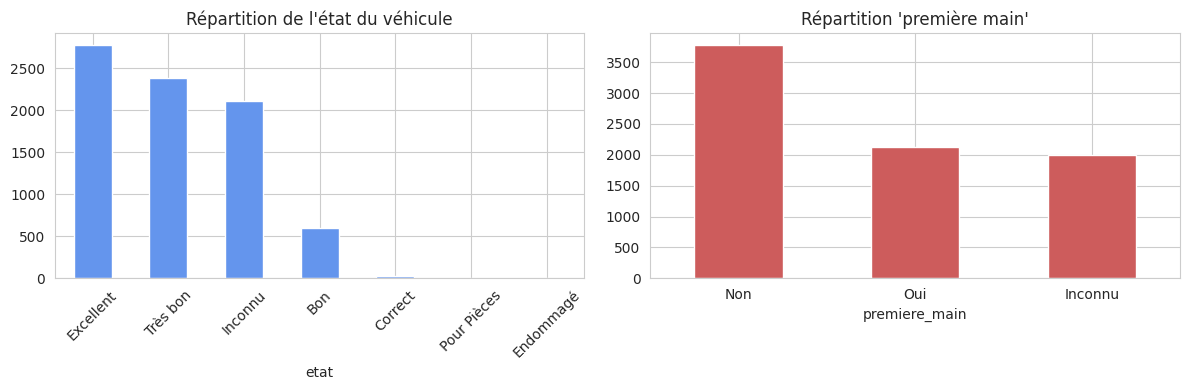

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['etat'].value_counts().plot(kind='bar', ax=axes[0], color='cornflowerblue')
axes[0].set_title("Répartition de l'état du véhicule")
axes[0].tick_params(axis='x', rotation=45)

df['premiere_main'].value_counts().plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title("Répartition 'première main'")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 14. Vérification finale et sauvegarde

Le dataset nettoyé est sauvegardé dans `data/processed/cars_clean.csv`, prêt à être
utilisé par `train.py` (Membre 2).

In [22]:
print("Aucune valeur manquante restante :", df.isna().sum().sum() == 0)
print("Shape finale du dataset nettoyé :", df.shape)
df.head()

Aucune valeur manquante restante : True
Shape finale du dataset nettoyé : (7903, 12)


,marque,modele,annee,kilometrage,carburant,boite_vitesses,puissance_fiscale,etat,ville,premiere_main,prix,age_vehicule
0,Fiat,Punto,2007,224999.5,Diesel,Manuelle,5,Très bon,Temara,Non,60000,19
1,Dacia,Autre,2013,424999.5,Diesel,Manuelle,6,Excellent,Temara,Non,70000,13
2,Dacia,Dokker,2014,164999.5,Diesel,Manuelle,6,Très bon,Casablanca,Inconnu,90000,12
3,Volkswagen,Touareg,2005,2499.5,Diesel,Automatique,10,Excellent,Casablanca,Oui,90000,21
4,Toyota,Prado,2007,224999.5,Diesel,Manuelle,12,Excellent,Dakhla,Non,97000,19


In [23]:
import os
os.makedirs('../data/processed', exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
print(f"Dataset sauvegardé -> {PROCESSED_PATH}")

Dataset sauvegardé -> ../data/processed/cars_clean.csv


## 15. Conclusion

**Décisions prises lors du nettoyage :**
- Suppression des colonnes non retenues (`Unnamed: 0`, `Lien`, `Secteur`, équipements, etc.) — seuls les 10 critères métier + le prix sont gardés.
- Suppression des annonces dupliquées (détectées via l'URL avant la sélection des colonnes).
- Conversion du kilométrage (tranches textuelles → valeur numérique médiane).
- Imputation des valeurs manquantes de `état`, `première main`, `boite_vitesses` par une catégorie `'Inconnu'` plutôt qu'une suppression de lignes.
- Regroupement des modalités rares de `modele` et `ville` sous `'Autre'` pour limiter la cardinalité.
- Suppression des outliers de prix via un garde-fou métier + un filtrage IQR sur le log-prix.
- Ajout d'une feature dérivée : `age_vehicule`.

Le dataset final est prêt pour l'entraînement (`train.py`).